In [26]:
#generate a python file from a jupyter one
!jupyter nbconvert --to script resizeImage.ipynb


[NbConvertApp] Converting notebook resizeImage.ipynb to script
[NbConvertApp] Writing 7259 bytes to resizeImage.py


In [9]:
from resizeImage import transform_data
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import cv2

class PoseNet(nn.Module):
    def __init__(self):
        super(PoseNet, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 112x112
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 56x56
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 28x28
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 32) 
        )

    def forward(self, x):
        x = self.conv(x)
        x = self.fc(x)
        return x

transform = transforms.Compose([
    transforms.ToTensor(),  # Convert to tensor (3, 224, 224)
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])  # Normalize RGB
])

In [13]:
image1, _, reverse1 = transform_data('image.png', [])
image2, _, reverse2 = transform_data('surfar.jpeg', [])


0: 640x448 1 person, 459.8ms
Speed: 2.1ms preprocess, 459.8ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 448)

0: 352x640 1 person, 2 surfboards, 372.3ms
Speed: 1.5ms preprocess, 372.3ms inference, 1.0ms postprocess per image at shape (1, 3, 352, 640)


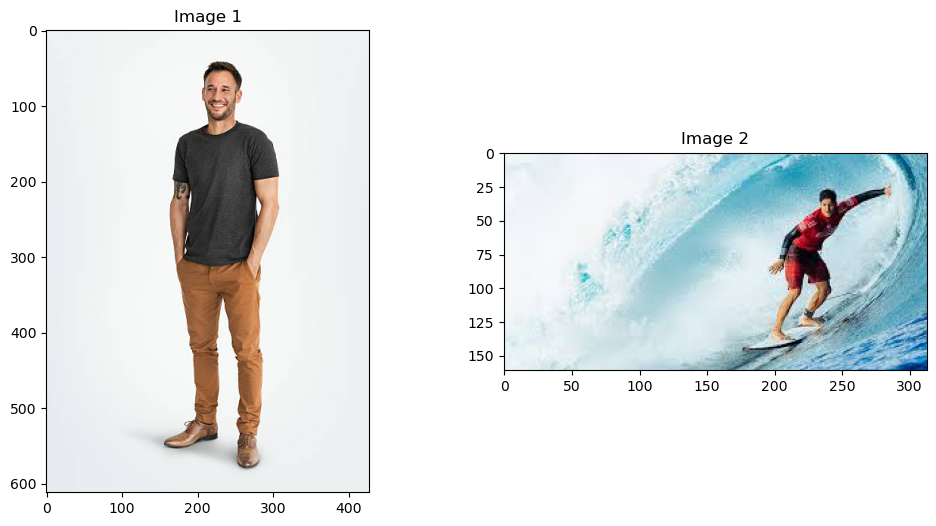

In [19]:
#print the image in plt
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].imshow(cv2.cvtColor(cv2.imread('image.png'), cv2.COLOR_BGR2RGB))
axs[0].set_title('Image 1')

axs[1].imshow(cv2.cvtColor(cv2.imread('surfar.jpeg'), cv2.COLOR_BGR2RGB))
axs[1].set_title('Image 2')

plt.show()



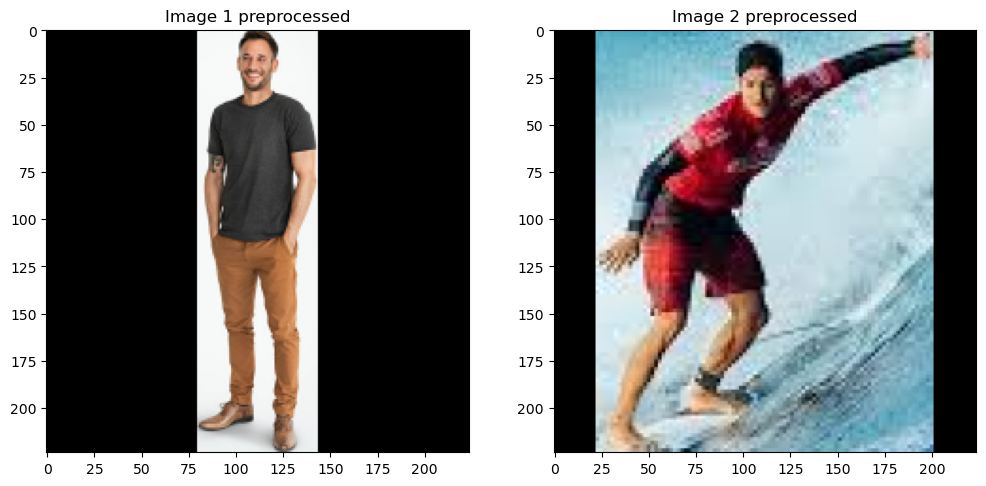

In [21]:
# show images after transformation
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].imshow(image1)
axs[0].set_title('Image 1 preprocessed')

axs[1].imshow(image2)
axs[1].set_title('Image 2 preprocessed')

plt.show()

In [22]:
def predict(image,model,file):
    model.load_state_dict(torch.load(file,map_location=torch.device('cpu')))
    model.eval()
    with torch.no_grad():
        img_tensor = transform(image).unsqueeze(0)
        output =model(img_tensor)*224

    keypoints = output.squeeze()  # Remove extra dimension if necessary
    points = [(keypoints[i].item(), keypoints[i+1].item()) for i in range(0, len(keypoints), 2)]
    return points




In [24]:
image1Pred = predict(image1,PoseNet(),'posev0178.pth')
image2Pred = predict(image2,PoseNet(),'posev0178.pth')

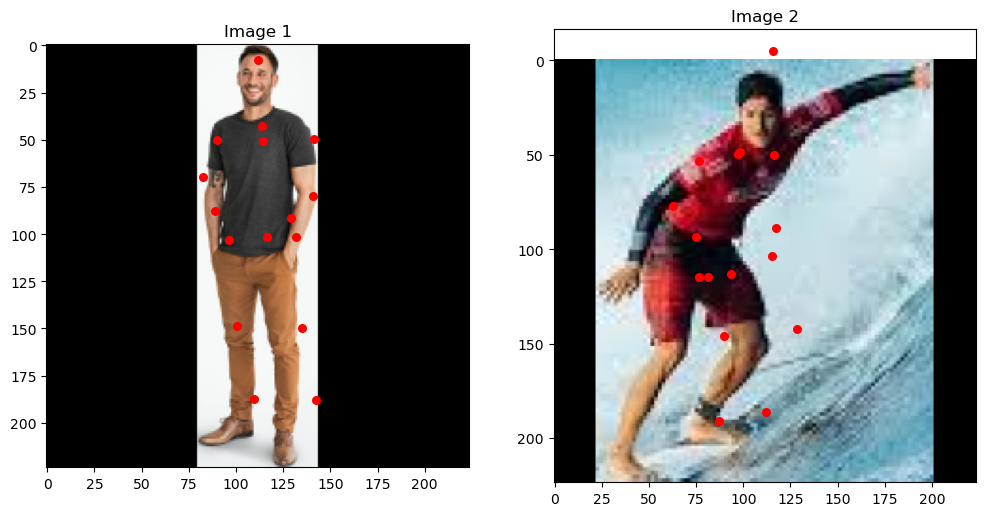

In [26]:
"show the images with the keypoints"
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].imshow(image1)
for point in image1Pred:
    axs[0].scatter(point[0], point[1], c='r', s=30)
axs[0].set_title('Image 1')

axs[1].imshow(image2)
for point in image2Pred:
    axs[1].scatter(point[0], point[1], c='r', s=30)
axs[1].set_title('Image 2')

plt.show()

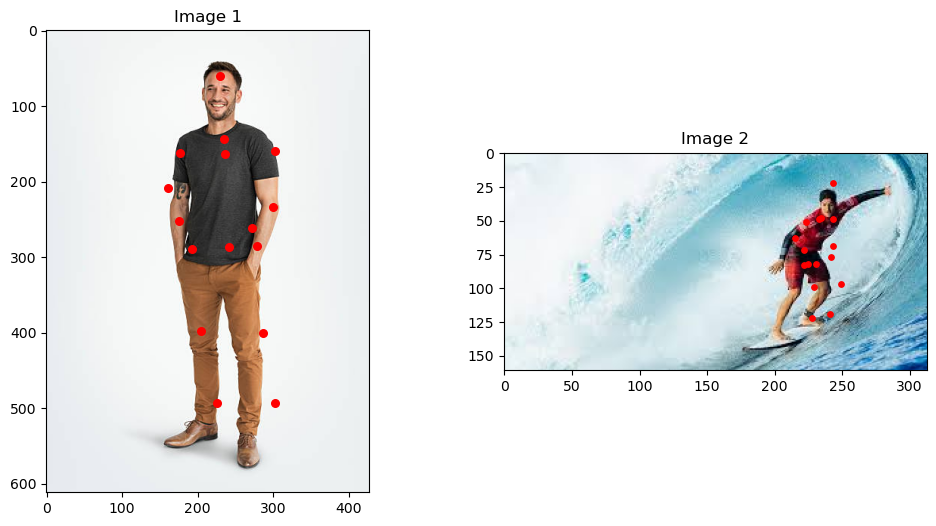

In [28]:
#show images with original size
original_img1 = [reverse1(x,y) for x, y in image1Pred]
original_img2 = [reverse2(x,y) for x, y in image2Pred]

fig, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].imshow(cv2.cvtColor(cv2.imread('image.png'), cv2.COLOR_BGR2RGB))
for point in original_img1:
    axs[0].scatter(point[0], point[1], c='r', s=30)
axs[0].set_title('Image 1')

axs[1].imshow(cv2.cvtColor(cv2.imread('surfar.jpeg'), cv2.COLOR_BGR2RGB))
for point in original_img2:
    axs[1].scatter(point[0], point[1], c='r', s=15)
axs[1].set_title('Image 2')

plt.show()

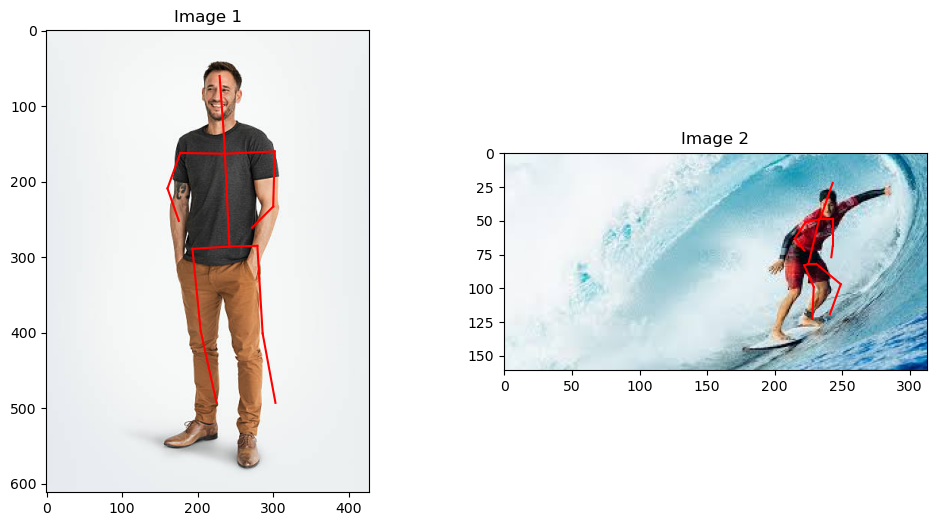

In [30]:
#connect the points with lines logically
keypoints = [
    ("r ankle_X", "r ankle_Y"),
    ("r knee_X", "r knee_Y"),
    ("r hip_X", "r hip_Y"),
    ("l hip_X", "l hip_Y"),
    ("l knee_X", "l knee_Y"),
    ("l ankle_X", "l ankle_Y"),
    ("pelvis_X", "pelvis_Y"),
    ("thorax_X", "thorax_Y"),
    ("upper neck_X", "upper neck_Y"),
    ("head top_X", "head top_Y"),
    ("r wrist_X", "r wrist_Y"),
    ("r elbow_X", "r elbow_Y"),
    ("r shoulder_X", "r shoulder_Y"),
    ("l shoulder_X", "l shoulder_Y"),
    ("l elbow_X", "l elbow_Y"),
    ("l wrist_X", "l wrist_Y")
]

connections = [
    (0, 1), (1, 2), (2, 6), (6, 3), (3, 4), (4, 5),  # legs
    (6, 7), (7, 8), (8, 9),  # body
    (7, 12), (12, 11), (11, 10),  # right arm
    (7, 13), (13, 14), (14, 15)  # left arm
]

fig, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].imshow(cv2.cvtColor(cv2.imread('image.png'), cv2.COLOR_BGR2RGB))
for connection in connections:
    start_point = original_img1[connection[0]]
    end_point = original_img1[connection[1]]
    axs[0].plot([start_point[0], end_point[0]], [start_point[1], end_point[1]], 'r')
axs[0].set_title('Image 1')

axs[1].imshow(cv2.cvtColor(cv2.imread('surfar.jpeg'), cv2.COLOR_BGR2RGB))
for connection in connections:
    start_point = original_img2[connection[0]]
    end_point = original_img2[connection[1]]
    axs[1].plot([start_point[0], end_point[0]], [start_point[1], end_point[1]], 'r')
axs[1].set_title('Image 2')

plt.show()